# DeepCluster

Caron et al., 2018: learn a representation by repeatedly clustering it and training the network to predict its own clusters.

Every **round**:
1. extract features of all paintings with the current network;
2. PCA (whitened) -> L2 normalise -> K-means with many clusters -> one **pseudo-label** per painting;
3. train one epoch with cross-entropy on those pseudo-labels (new classifier head every round, sampling balanced over clusters).

At the end the network is used like any other representation model: embed, cluster with a small K, evaluate against the metadata.

All parameters are in the **Config** cell. Training and evaluation use the same `N_PAINTINGS` paintings from `SPLIT`.

In [1]:
import gc
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
import umap
from sklearn.cluster import DBSCAN, HDBSCAN, KMeans
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_mutual_info_score, adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer, normalize
from torch.utils.data import DataLoader, Subset
from torchvision.transforms import v2
from tqdm.auto import tqdm

if "google.colab" in sys.modules:
    SRC = Path("/content/Project/src")          # or /content/drive/MyDrive/.../Project/src
else:
    SRC = Path.cwd().parents[1]                 # training/ -> restore_pipeline/ -> src/

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from restore_pipeline.dataprocessing.dataloading import RESIZE_128, DataConfig, SobelEdges, get_splits, get_splits_dataloaders
from restore_pipeline.clustering.plotting import plot_cluster_samples, plot_clusters_2d, plot_kmeans_sweep, umap_project
from restore_pipeline.clustering.utils import kmeans_sweep

# Config

In [13]:
# ---------------- Data ----------------
DATA_DIR    = Path("../data")
USE_SOBEL   = False                # True: grayscale Sobel edges, no colour (as in the paper) | False: RGB
IMG_SIZE    = 128                 # RESIZE_128 is used, so keep this at 128
BATCH_SIZE  = 64
NUM_WORKERS = 2
SEED        = 42

SPLIT         = "train"           # paintings DeepCluster is trained AND evaluated on
N_PAINTINGS   = None #40_000            # None = whole split
LABEL_COLUMNS = ["style", "genre", "artist"]   # metadata for monitoring and evaluation (never used in training)

# ---------------- DeepCluster ----------------
FEAT_DIM     = 512                # representation size (input of the classifier, used for clustering)
N_PSEUDO     = 200                # K-means clusters for the pseudo-labels: deliberately MORE than real classes (paper: 10x)
PCA_DIM      = 256                # paper: 256
ROUNDS       = 30                 # one round = re-cluster everything + one training epoch
LR           = 0.03               # SGD, paper values
MOMENTUM     = 0.9
WEIGHT_DECAY = 1e-5
CROP_SCALE   = (0.4, 1.0)         # RandomResizedCrop scale range (per-image augmentation)

# ---------------- Final evaluation ----------------
K_SWEEP = range(2, 200, 10)
K       = 50                       # final clustering of the learned representation

# ---------------- Density-based clustering (UMAP + DBSCAN / HDBSCAN) ----------------
DENSITY_METHOD           = "hdbscan"   # "hdbscan" | "dbscan"
UMAP_DIM                 = 10     # density clustering runs in this UMAP space (density is meaningless in 64+ dims). Lower = less noise
UMAP_NEIGHBORS           = 30     # larger = more global structure, fewer / bigger clusters
MIN_SAMPLES              = 5      # neighbours needed to be a core point: the main knob for the NOISE share (lower = less noise)
HDBSCAN_MIN_CLUSTER_SIZE = 50     # HDBSCAN: smallest group accepted as a cluster
HDBSCAN_SELECTION        = "eom"  # HDBSCAN: "eom" (fewer, larger clusters) | "leaf" (many small ones, usually more noise)
DBSCAN_EPS               = None   # DBSCAN: None = EPS_QUANTILE of the k-distance curve (plotted)
EPS_QUANTILE             = 0.5
SHOW_CLUSTERS            = 12     # sample grid: only the largest clusters

def make_preprocess():
    """Embedding -> clustering features for the final evaluation."""
    return make_pipeline(
        PCA(PCA_DIM, whiten=True, random_state=SEED),
        Normalizer(norm="l2"),
    )

CHECKPOINT_DIR = Path("checkpoints")
SAVE_TO = None                    # e.g. CHECKPOINT_DIR / "deepcluster_sobel.pt"

IN_CHANNELS = 2 if USE_SOBEL else 3
TRANSFORM = v2.Compose([*RESIZE_128.transforms, SobelEdges()]) if USE_SOBEL else RESIZE_128
device = "cuda" if torch.cuda.is_available() else "cpu"
RUN_NAME = f"DeepCluster ({'Sobel' if USE_SOBEL else 'RGB'}, {N_PSEUDO} pseudo-clusters)"

# Data

In [3]:
data_cfg = DataConfig(
    processed_path=DATA_DIR / "wikiart_train_processed",
    cache_dir=str(DATA_DIR),
    seed=SEED,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    shuffle_train=False,
    transform_train=TRANSFORM,
    transform_val=TRANSFORM,
    transform_test=TRANSFORM,
    transform_full=TRANSFORM,
)
splits = dict(zip(["train", "val", "test"], get_splits(data_cfg)))                    # raw rows: images + metadata
image_datasets = {name: loader.dataset                                                # transformed images only
                  for name, loader in zip(["train", "val", "test"], get_splits_dataloaders(data_cfg))}


def sample_indices(n_total: int, n: int | None) -> np.ndarray:
    """`n` random row indices, sorted (rows keep dataset order). All rows if `n` is None."""
    if n is None or n >= n_total:
        return np.arange(n_total)
    return np.sort(np.random.default_rng(SEED).choice(n_total, size=n, replace=False))


def make_loader(dataset, idx: np.ndarray, persistent: bool = False) -> DataLoader:
    """Batches of {'image': (B, C, H, W)} from rows `idx` of `dataset`, in exactly that order."""
    return DataLoader(
        Subset(dataset, idx.tolist()),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=False,                 # pinned (page-locked) RAM ran out on Windows over several rounds
        persistent_workers=persistent and NUM_WORKERS > 0,
    )


images = image_datasets[SPLIT]
cluster_idx = sample_indices(len(images), N_PAINTINGS)
n_paintings = len(cluster_idx)

# Fixed order: row i of every feature / label array is painting cluster_idx[i]
cluster_loader = make_loader(images, cluster_idx, persistent=True)
ds_cluster = splits[SPLIT].select(cluster_idx)
meta = ds_cluster.select_columns(LABEL_COLUMNS).to_pandas()

print(f"{SPLIT}: {n_paintings} paintings ({len(cluster_loader)} batches), {IN_CHANNELS} input channels")

train: 82321 paintings (1287 batches), 3 input channels


# Model

In [4]:
def conv_bn_relu(c_in: int, c_out: int) -> list[nn.Module]:
    return [nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True)]


class Backbone(nn.Module):
    """Small VGG-style CNN -> global average pool -> MLP. Its output is the representation."""

    def __init__(self, in_channels: int = 2, feat_dim: int = 512):
        super().__init__()
        self.conv = nn.Sequential(
            *conv_bn_relu(in_channels, 64), nn.MaxPool2d(2),                        # 128 -> 64
            *conv_bn_relu(64, 128), nn.MaxPool2d(2),                                # 64 -> 32
            *conv_bn_relu(128, 256), *conv_bn_relu(256, 256), nn.MaxPool2d(2),     # 32 -> 16
            *conv_bn_relu(256, 512), *conv_bn_relu(512, 512), nn.MaxPool2d(2),     # 16 -> 8
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
        )
        self.mlp = nn.Sequential(nn.Linear(512, feat_dim), nn.ReLU(inplace=True))

    def forward(self, x):
        return self.mlp(self.conv(x))


torch.manual_seed(SEED)
backbone = Backbone(IN_CHANNELS, FEAT_DIM).to(device)
print(f"{sum(p.numel() for p in backbone.parameters()) / 1e6:.2f}M parameters")

# Per-image augmentation on the GPU: every painting gets its own random crop and flip.
augment = v2.Compose([
    v2.RandomResizedCrop(IMG_SIZE, scale=CROP_SCALE, antialias=True),
    v2.RandomHorizontalFlip(),
])

4.77M parameters


# DeepCluster functions

* `extract_features`: the representation of every painting, in the fixed order of `cluster_loader`.
* `cluster_features`: the paper's recipe, PCA (whitened) -> L2 normalise -> K-means. sklearn's K-means already relocates empty clusters, so the paper's empty-cluster trick is not needed.
* `balanced_order`: samples paintings with weight `1 / cluster size`, i.e. uniformly over **clusters**. Without it one huge cluster dominates and the network learns to predict it for everything.
* `train_one_round`: a **new** classifier head every round, because cluster ids are arbitrary and change between rounds.

In [5]:
@torch.inference_mode()
def extract_features(model: nn.Module, loader: DataLoader, desc: str = "features") -> np.ndarray:
    model.eval()
    return torch.cat([model(batch["image"].to(device, non_blocking=True)).float().cpu()
                      for batch in tqdm(loader, desc=desc, leave=False)]).numpy()


def cluster_features(features: np.ndarray, k: int, seed: int) -> np.ndarray:
    reduced = PCA(min(PCA_DIM, features.shape[1]), whiten=True, random_state=seed).fit_transform(features)
    return KMeans(n_clusters=k, n_init=1, random_state=seed).fit_predict(normalize(reduced))


def balanced_order(pseudo: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    sizes = np.bincount(pseudo, minlength=N_PSEUDO)
    weights = 1.0 / sizes[pseudo]
    return rng.choice(len(pseudo), size=len(pseudo), replace=True, p=weights / weights.sum())


def train_one_round(model: nn.Module, pseudo: np.ndarray, rng: np.random.Generator, desc: str) -> float:
    classifier = nn.Linear(FEAT_DIM, N_PSEUDO).to(device)
    params = list(model.parameters()) + list(classifier.parameters())
    optimizer = torch.optim.SGD(params, lr=LR, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)

    order = balanced_order(pseudo, rng)
    targets = torch.from_numpy(pseudo[order]).long()
    loader = make_loader(images, cluster_idx[order])     # rows in `order`, so batch b <-> targets[b*B:(b+1)*B]

    model.train()
    total = 0.0
    progress = tqdm(loader, desc=desc, leave=False)
    for b, batch in enumerate(progress):
        x = batch["image"].to(device, non_blocking=True)
        x = torch.stack([augment(img) for img in x])
        y = targets[b * BATCH_SIZE:(b + 1) * BATCH_SIZE].to(device)

        loss = F.cross_entropy(classifier(model(x)), y)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(x)
        progress.set_postfix(loss=f"{loss.item():.3f}")
    del loader, batch, x, y          # shut down this round's workers and free its batches now, not at some later GC
    return total / len(order)

# Training

Monitoring (never used for training decisions):
* **NMI vs previous round**: how much the pseudo-labels change. It should rise and level off; close to 1 from the very start (with the loss near 0) suggests the network found a shortcut.
* **NMI vs style**: whether the pseudo-labels become more meaningful.
* **largest cluster**: share of paintings in the biggest pseudo-cluster, to spot collapse.

In [6]:
rng = np.random.default_rng(SEED)
known_style = meta["style"].notna().to_numpy()
previous = None
log = []

rounds_bar = tqdm(range(ROUNDS), desc="DeepCluster rounds")
for round_ in rounds_bar:
    features = extract_features(backbone, cluster_loader, desc=f"round {round_}: features")
    rounds_bar.set_postfix_str("k-means")
    pseudo = cluster_features(features, N_PSEUDO, seed=SEED + round_)

    row = {
        "round": round_,
        "nmi_prev_round": normalized_mutual_info_score(previous, pseudo) if previous is not None else np.nan,
        "nmi_style": normalized_mutual_info_score(meta["style"][known_style], pseudo[known_style]),
        "largest_cluster": np.bincount(pseudo).max() / len(pseudo),
    }
    previous = pseudo

    rounds_bar.set_postfix_str("training")
    row["loss"] = train_one_round(backbone, pseudo, rng, desc=f"round {round_}: training")
    log.append(row)
    gc.collect()                    # collect the finished round's loader before the next one starts
    rounds_bar.set_postfix(loss=f"{row['loss']:.3f}", nmi_style=f"{row['nmi_style']:.3f}")
    tqdm.write(f"round {round_}: CE {row['loss']:.3f} | NMI vs prev {row['nmi_prev_round']:.3f} | "
               f"NMI vs style {row['nmi_style']:.3f} | largest cluster {row['largest_cluster']:.1%}")

log = pd.DataFrame(log)

DeepCluster rounds:   0%|          | 0/30 [00:00<?, ?it/s]

round 0: features:   0%|          | 0/1287 [00:12<?, ?it/s]

round 0: training:   0%|          | 0/1287 [00:12<?, ?it/s]

round 0: CE 4.490 | NMI vs prev nan | NMI vs style 0.050 | largest cluster 1.2%


round 1: features:   0%|          | 0/1287 [00:00<?, ?it/s]

round 1: training:   0%|          | 0/1287 [00:12<?, ?it/s]

... (81 outputs left out)

round 28: CE 2.205 | NMI vs prev 0.627 | NMI vs style 0.126 | largest cluster 0.9%


round 29: features:   0%|          | 0/1287 [00:00<?, ?it/s]

round 29: training:   0%|          | 0/1287 [00:10<?, ?it/s]

round 29: CE 2.192 | NMI vs prev 0.629 | NMI vs style 0.128 | largest cluster 0.8%


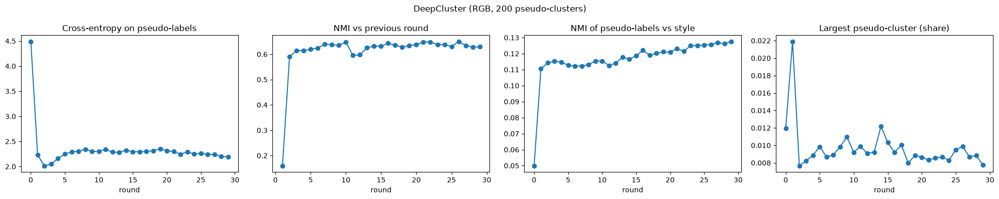

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (column, title) in zip(axes, [
    ("loss", "Cross-entropy on pseudo-labels"),
    ("nmi_prev_round", "NMI vs previous round"),
    ("nmi_style", "NMI of pseudo-labels vs style"),
    ("largest_cluster", "Largest pseudo-cluster (share)"),
]):
    ax.plot(log["round"], log[column], marker="o")
    ax.set(title=title, xlabel="round")
fig.suptitle(RUN_NAME)
plt.tight_layout()
plt.show()

# Evaluation

The learned representation is clustered again with a **small** K (the pseudo-label K only drives training), exactly like the autoencoder embeddings in `test_representation_on_cluster.ipynb`.

features:   0%|          | 0/1287 [00:00<?, ?it/s]

embedding 512 -> features 256


K-means sweep:   0%|          | 0/20 [00:00<?, ?it/s]

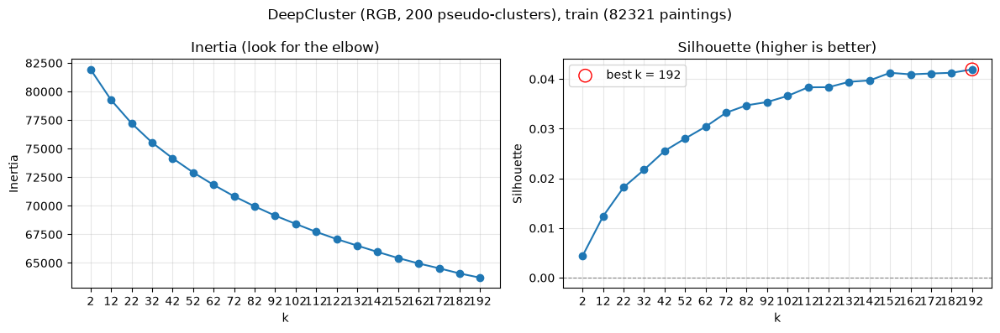

In [14]:
embed = extract_features(backbone, cluster_loader)
preprocess = make_preprocess()
features = preprocess.fit_transform(embed)
print(f"embedding {embed.shape[1]} -> features {features.shape[1]}")

sweep = kmeans_sweep(features, K_SWEEP, seed=SEED)
plot_kmeans_sweep(sweep, title=f"{RUN_NAME}, {SPLIT} ({len(features)} paintings)")
plt.show()

In [9]:
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(features)
labels = kmeans.labels_

silhouette = silhouette_score(features, labels, sample_size=min(10_000, len(labels)), random_state=SEED)
print(f"Silhouette (k={K}) = {silhouette:.3f} on {len(labels)} paintings")
print("cluster sizes:", np.bincount(labels, minlength=K))

rows = []
for column in LABEL_COLUMNS:
    known = meta[column].notna().to_numpy()          # preprocessing set some labels to None
    y_true, y_pred = meta[column][known].to_numpy(), labels[known]
    rows.append({
        "labels": column,
        "classes": len(np.unique(y_true)),
        "paintings": int(known.sum()),
        "NMI": normalized_mutual_info_score(y_true, y_pred),
        "AMI": adjusted_mutual_info_score(y_true, y_pred),
        "ARI": adjusted_rand_score(y_true, y_pred),
    })
display(pd.DataFrame(rows).round(3))

Silhouette (k=50) = 0.028 on 82321 paintings
cluster sizes: [ 1466  1537  1917  1402  1845  1703  1932  1756   768   999  1960   891
   898  1478  1375  1129  1053  1786  1414  2256 10711  1532  1288  1319
  1528  1449  1378  1992  1141  1687   993   867   807  1632  1467  1271
  1292  1552  1291  1635  1873  1477  1001  1725  2254  1467  1622  2012
   836  1657]


,labels,classes,paintings,NMI,AMI,ARI
0,style,136,82301,0.095,0.085,0.006
1,genre,42,82301,0.077,0.074,0.012
2,artist,2200,82301,0.215,0.137,0.006


c:\Users\MatG\Desktop\UniStuff\MAGI\Semestr II\UczenieNienadzorowane\Project\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


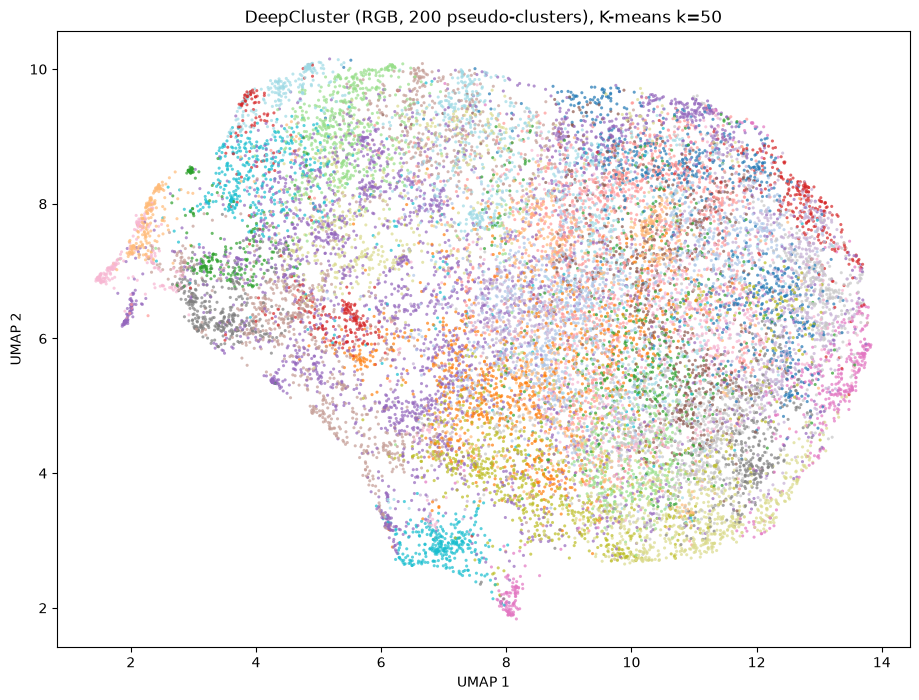

In [10]:
embedding_2d, idx_2d = umap_project(features, seed=SEED)
plot_clusters_2d(embedding_2d, labels[idx_2d], title=f"{RUN_NAME}, K-means k={K}")
plt.show()




In [11]:
plot_cluster_samples(ds_cluster, labels, n_per_cluster=8, captions=meta["style"], seed=SEED)

# Density-based clustering: UMAP + DBSCAN / HDBSCAN

K-means always cuts the data into `K` pieces, even if it is one continuous cloud. DBSCAN / HDBSCAN look for **dense regions** instead, decide the number of clusters themselves and leave paintings between dense regions unassigned (**noise**, label `-1`).

1. UMAP (`min_dist=0`) to `UMAP_DIM` dimensions: keeps neighbourhoods and packs neighbours tightly, so dense regions are easier to find;
2. DBSCAN (one global density threshold `eps`) or HDBSCAN (adapts to clusters of different density, usually the better choice).

The table compares, on the **same** paintings:
* the density clusters on the non-noise paintings ("cores") vs K-means on those same paintings;
* the density clusters with every noise painting **assigned to the cluster of its nearest clustered neighbours** vs K-means on all paintings.

Silhouettes are all computed in the UMAP space (inflated by UMAP, so comparable only within this table).

In [ ]:
umap_space = umap.UMAP(n_components=UMAP_DIM, n_neighbors=UMAP_NEIGHBORS, min_dist=0.0,
                       random_state=SEED).fit_transform(features)

if DENSITY_METHOD == "dbscan":
    distances, _ = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(umap_space).kneighbors(umap_space)
    k_dist = np.sort(distances[:, -1])
    eps = DBSCAN_EPS if DBSCAN_EPS is not None else float(np.quantile(k_dist, EPS_QUANTILE))
    plt.plot(k_dist)
    plt.axhline(eps, color="red", linestyle="--", label=f"eps = {eps:.3f}")
    plt.title(f"k-distance ({MIN_SAMPLES}-th neighbour), sorted: a good eps sits near the bend")
    plt.xlabel("paintings")
    plt.ylabel("distance")
    plt.legend()
    plt.show()
    density = DBSCAN(eps=eps, min_samples=MIN_SAMPLES)
elif DENSITY_METHOD == "hdbscan":
    density = HDBSCAN(min_cluster_size=HDBSCAN_MIN_CLUSTER_SIZE, min_samples=MIN_SAMPLES,
                      cluster_selection_method=HDBSCAN_SELECTION)
else:
    raise ValueError(f"unknown DENSITY_METHOD: {DENSITY_METHOD}")

density_labels = density.fit_predict(umap_space)
noise = density_labels == -1
n_density = len(np.unique(density_labels[~noise]))
print(f"{DENSITY_METHOD}: {n_density} clusters | noise {noise.sum()} paintings ({noise.mean():.1%})")
print("cluster sizes (largest first):", np.sort(np.bincount(density_labels[~noise]))[::-1] if n_density else [])

# Every noise painting -> majority cluster of its 15 nearest clustered paintings (in the same UMAP space)
density_labels_all = density_labels.copy()
if n_density >= 1 and noise.any():
    knn = KNeighborsClassifier(n_neighbors=15).fit(umap_space[~noise], density_labels[~noise])
    density_labels_all[noise] = knn.predict(umap_space[noise])

In [ ]:
def score(name: str, pred: np.ndarray, rows_mask: np.ndarray) -> dict:
    row = {"method": name, "paintings": int(rows_mask.sum()), "clusters": len(np.unique(pred[rows_mask]))}
    if row["clusters"] >= 2:
        row["silhouette (UMAP)"] = silhouette_score(umap_space[rows_mask], pred[rows_mask],
                                                    sample_size=min(10_000, int(rows_mask.sum())), random_state=SEED)
    for column in LABEL_COLUMNS:
        known = meta[column].notna().to_numpy() & rows_mask
        row[f"AMI {column}"] = adjusted_mutual_info_score(meta[column][known], pred[known])
    for column in LABEL_COLUMNS:
        known = meta[column].notna().to_numpy() & rows_mask
        row[f"ARI {column}"] = adjusted_rand_score(meta[column][known], pred[known])
    return row


everyone = np.ones(len(labels), dtype=bool)
table = [
    score(f"{DENSITY_METHOD}, cores only ({noise.mean():.0%} noise left out)", density_labels, ~noise),
    score(f"K-means k={K}, same paintings", labels, ~noise),
    score(f"{DENSITY_METHOD} + noise assigned, all paintings", density_labels_all, everyone),
    score(f"K-means k={K}, all paintings", labels, everyone),
]
display(pd.DataFrame(table).set_index("method").round(3))

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(30, 8))
plot_clusters_2d(embedding_2d, density_labels[idx_2d], title=f"{DENSITY_METHOD}: {n_density} clusters, {noise.mean():.0%} noise (grey)", ax=axes[0])
plot_clusters_2d(embedding_2d, density_labels_all[idx_2d], title=f"{DENSITY_METHOD}, noise assigned", ax=axes[1])
plot_clusters_2d(embedding_2d, labels[idx_2d], title=f"K-means k={K}", ax=axes[2])
plt.tight_layout()
plt.show()

In [ ]:
# What each density cluster is "about": most common genre / style and their shares (-1 = noise)
def top(s: pd.Series):
    return s.value_counts().index[0] if s.notna().any() else None

def top_share(s: pd.Series):
    return s.value_counts(normalize=True).iloc[0] if s.notna().any() else np.nan

density_summary = (
    pd.DataFrame({"cluster": density_labels, "genre": meta["genre"], "style": meta["style"]})
    .groupby("cluster")
    .agg(size=("genre", "size"),
         top_genre=("genre", top), top_genre_share=("genre", top_share),
         top_style=("style", top), top_style_share=("style", top_share))
    .sort_values("size", ascending=False)
)
display(density_summary.round(2))

In [ ]:
# Sample grid of the SHOW_CLUSTERS largest density clusters (noise left out)
largest = density_summary.drop(index=-1, errors="ignore").index[:SHOW_CLUSTERS]
rows_shown = np.flatnonzero(np.isin(density_labels, largest))
plot_cluster_samples(ds_cluster.select(rows_shown), density_labels[rows_shown], n_per_cluster=8,
                     captions=meta["style"].iloc[rows_shown].reset_index(drop=True), seed=SEED)

In [12]:
# Reload: backbone = Backbone(IN_CHANNELS, FEAT_DIM); backbone.load_state_dict(torch.load(path)["state_dict"])
if SAVE_TO is not None:
    Path(SAVE_TO).parent.mkdir(parents=True, exist_ok=True)
    torch.save({
        "config": {
            "use_sobel": USE_SOBEL, "in_channels": IN_CHANNELS, "feat_dim": FEAT_DIM, "n_pseudo": N_PSEUDO,
            "pca_dim": PCA_DIM, "rounds": ROUNDS, "lr": LR, "split": SPLIT, "n_paintings": N_PAINTINGS, "seed": SEED,
        },
        "state_dict": backbone.state_dict(),
        "log": log.to_dict(orient="list"),
    }, SAVE_TO)
    print(f"saved {SAVE_TO}")